# BÀI THỰC HÀNH SỐ 1 - PHẦN 1 - BÀI 2 (Trang 15–17)
## Khảo sát và Tiền xử lý dữ liệu Titanic (`titanic.csv`)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Nhập và thống kê dữ liệu Titanic, trực quan hóa mối liên hệ giữa các thuộc tính với khả năng sống sót (`survived`), xử lý giá trị thiếu, chuẩn hóa/rời rạc hóa thuộc tính và tạo thuộc tính mới.

In [1]:
import os
import sys
import subprocess

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"

DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"

def get_dataset_path(filename: str) -> str:
    """Tìm đường dẫn tập dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
        check=True,
    )
    if not os.path.exists(local_path):
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")
    return local_path

data_path = get_dataset_path("titanic.csv")
print(f"{STUDENT_NAME} - {MSSV}")
print(f"Đường dẫn dữ liệu: {data_path}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn dữ liệu: Dataset\titanic.csv


## Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

# linear algebra
import numpy as np

# data processing
import pandas as pd

# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
from IPython.display import display

# Đọc dữ liệu Titanic với kiểu dữ liệu chỉ định theo hướng dẫn
with open(data_path, encoding="utf-8") as f:
    df = pd.read_csv(f, dtype={"age": np.float64, "sibsp": np.int64, "parch": np.int64})

print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n--- 12 dòng đầu tiên (head(12)) ---")
display(df.head(12))

print("\n--- Thông tin cấu trúc dữ liệu (info()) ---")
df.info()

print("\n--- Thống kê mô tả các thuộc tính định lượng (describe()) ---")
display(df.describe())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước dữ liệu: 1309 dòng, 14 cột

--- 12 dòng đầu tiên (head(12)) ---


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"



--- Thông tin cấu trúc dữ liệu (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 210.3 KB

--- Thống kê mô tả các thuộc tính định lượng (describe()) ---


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


**Nhận xét Câu 1:**
- Tập dữ liệu gồm **1.309** hành khách và **14** thuộc tính (`pclass`, `survived`, `name`, `sex`, `age`, `sibsp`, `parch`, `ticket`, `fare`, `cabin`, `embarked`, `boat`, `body`, `home.dest`).
- Tỉ lệ sống sót trung bình (`survived` mean) là khoảng **38.2%**.
- Thuộc tính `age` có `1.046/1.309` giá trị không rỗng (trung bình `29.88` tuổi, nhỏ nhất `0.17` tuổi, lớn nhất `80` tuổi); `fare` có `1.308/1.309` giá trị không rỗng (dao động từ `0` đến `512.33`).

## Câu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=["Total", "%"])

print("--- Top 5 thuộc tính có nhiều giá trị rỗng nhất ---")
display(missing_data.head(5))

Nguyễn Phạm Bảo Khanh - 6451071033
--- Top 5 thuộc tính có nhiều giá trị rỗng nhất ---


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


**Nhận xét Câu 2:**
5 thuộc tính có số lượng giá trị bị thiếu (`null`) nhiều nhất lần lượt là:
1. **`body`**: `1.188` giá trị thiếu (**90.8%**) — thiếu dữ liệu rất nghiêm trọng (chỉ ghi nhận số hiệu thi thể đối với nạn nhân được tìm thấy), sẽ gây nhiễu hoặc rò rỉ thông tin nếu giữ lại.
2. **`cabin`**: `1.014` giá trị thiếu (**77.5%**) — tuy thiếu nhiều nhưng ký tự đầu tiên cho biết boong tàu (`deck`), có thể trích xuất trước khi xóa cột gốc.
3. **`boat`**: `823` giá trị thiếu (**62.9%**) — số hiệu xuồng cứu sinh (chỉ có ở người lên xuồng), cần loại bỏ khi tiền xử lý.
4. **`home.dest`**: `564` giá trị thiếu (**43.1%**) — nơi đi/đến rời rạc, thiếu gần một nửa dữ liệu nên có thể loại bỏ.
5. **`age`**: `263` giá trị thiếu (**20.1%**) — thuộc tính nhân khẩu học quan trọng ảnh hưởng đến khả năng sống sót, cần được điền khuyết hợp lý thay vì xóa bỏ.

Ngoài ra còn có `embarked` (thiếu `2` dòng) và `fare` (thiếu `1` dòng) sẽ được xử lý ở các bước tiếp theo.

## Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa Độ tuổi (`age`), Giới tính (`sex`) và Khả năng sống sót (`survived`)

Nguyễn Phạm Bảo Khanh - 6451071033


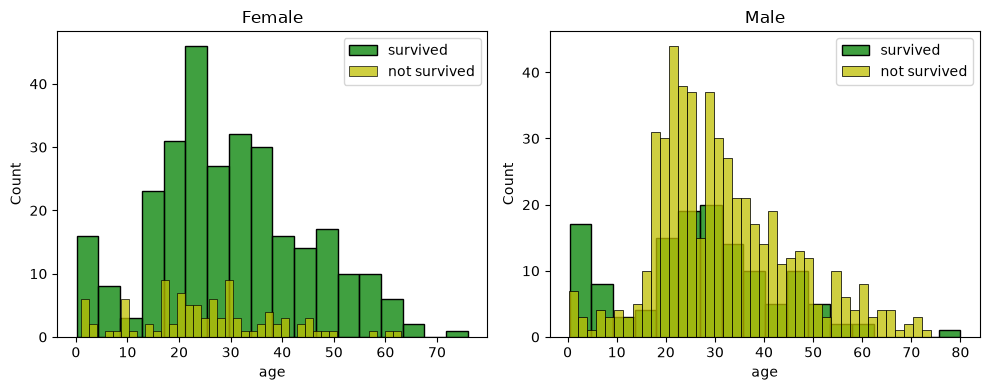

Tỉ lệ sống sót tổng thể theo giới tính:


,count,mean
sex,,
female,466,0.727
male,843,0.191


In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

survived = "survived"
not_survived = "not survived"
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

women = df[df["sex"] == "female"]
men = df[df["sex"] == "male"]

ax = sns.histplot(
    women[women["survived"] == 1]["age"].dropna(),
    bins=18, label=survived, ax=axes[0], kde=False, color="g"
)
ax = sns.histplot(
    women[women["survived"] == 0]["age"].dropna(),
    bins=40, label=not_survived, ax=axes[0], kde=False, color="y"
)
ax.legend()
ax.set_title("Female")

ax = sns.histplot(
    men[men["survived"] == 1]["age"].dropna(),
    bins=18, label=survived, ax=axes[1], kde=False, color="g"
)
ax = sns.histplot(
    men[men["survived"] == 0]["age"].dropna(),
    bins=40, label=not_survived, ax=axes[1], kde=False, color="y"
)
ax.legend()
ax.set_title("Male")

plt.tight_layout()
plt.show()

print("Tỉ lệ sống sót tổng thể theo giới tính:")
display(df.groupby("sex")["survived"].agg(["count", "mean"]).round(3))

**Nhận xét Câu 3:**
- Nhìn chung, tỉ lệ sống sót của nữ giới (**72.7%** trên 466 hành khách) cao vượt trội so với nam giới (**19.1%** trên 843 hành khách) ở hầu hết các nhóm tuổi (phù hợp nguyên tắc ưu tiên *"Phụ nữ và trẻ em trước"*).
- Đối với **nam (`Male`)**: xác suất sống sót tương đối cao ở độ tuổi trẻ em từ **1 đến 10 tuổi** (~55.6%), trong khi số lượng nam không sống sót tập trung cao nhất ở độ tuổi thanh niên từ **18 đến 27 tuổi**.
- Đối với **nữ (`Female`)**: cơ hội sống sót rất cao đặc biệt ở độ tuổi từ **12 đến 40 tuổi** (~75.4%), áp đảo số trường hợp tử vong ở mọi nhóm tuổi.

## Câu 4: Khảo sát sự liên quan giữa Cổng lên tàu (`embarked`) và Loại vé (`pclass`) với Khả năng sống sót (`survived`), phân biệt theo Giới tính (`sex`)

Nguyễn Phạm Bảo Khanh - 6451071033


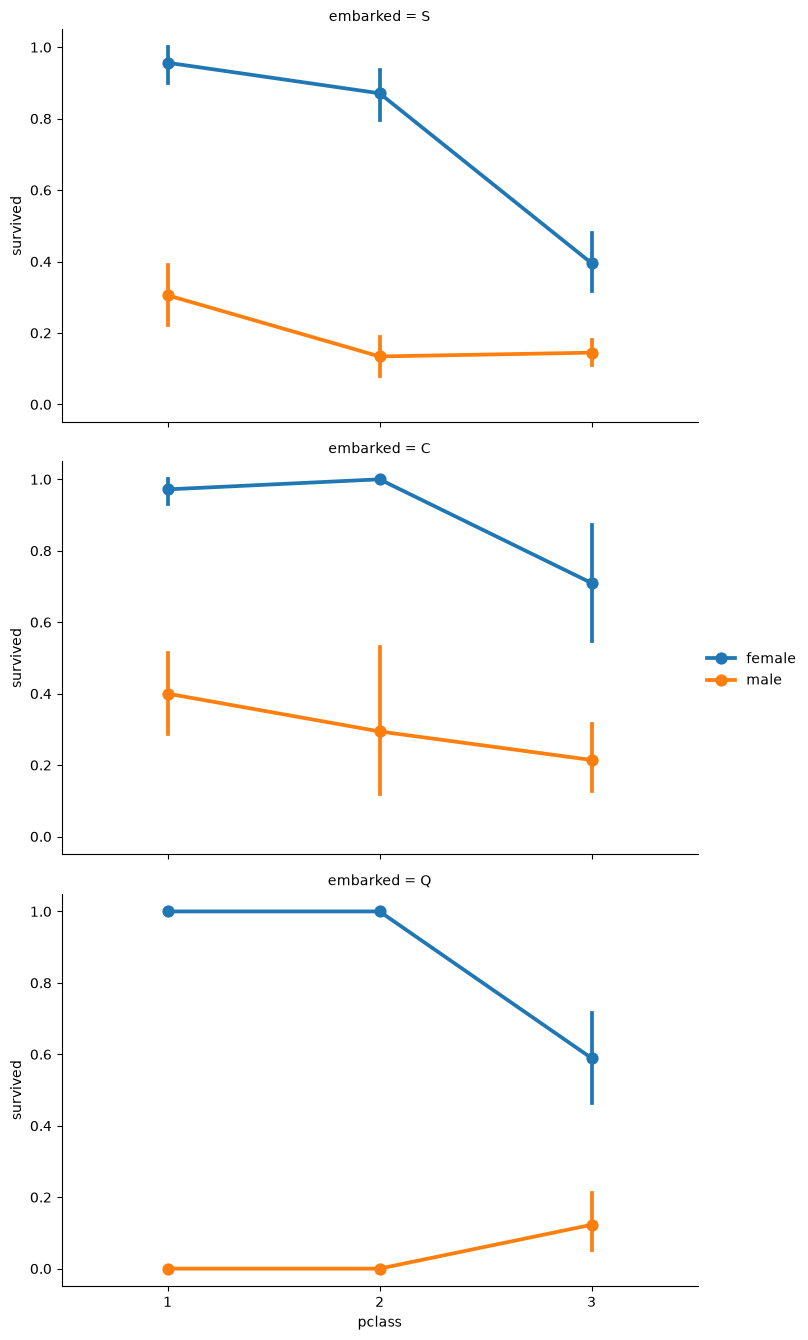

Tỉ lệ sống sót theo (embarked, sex, pclass):


count   mean
embarked sex    pclass              
C        female 1          71  0.972
                2          11  1.000
                3          31  0.710
         male   1          70  0.400
                2          17  0.294
                3          70  0.214
Q        female 1           2  1.000
                2           2  1.000
                3          56  0.589
         male   1           1  0.000
                2           5  0.000
                3          57  0.123
S        female 1          69  0.957
                2          93  0.871
                3         129  0.395
         male   1         108  0.306
                2         149  0.134
                3         366  0.145

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

# Truyền order=[1, 2, 3] và hue_order=['female', 'male'] để cố định thứ tự trục và màu sắc nhất quán giữa các facet trong seaborn 0.13.2
fg = sns.FacetGrid(df, row="embarked", height=4.5, aspect=1.6)
fg.map(
    sns.pointplot,
    "pclass",
    "survived",
    "sex",
    palette="tab10",
    order=[1, 2, 3],
    hue_order=["female", "male"],
)
fg.add_legend()
plt.show()

print("Tỉ lệ sống sót theo (embarked, sex, pclass):")
display(df.groupby(["embarked", "sex", "pclass"])["survived"].agg(["count", "mean"]).round(3))

**Nhận xét 4.1 (`embarked`, `pclass`, `sex` vs `survived`):**
- Thuộc tính `embarked` và `sex` có mối liên hệ rõ rệt với khả năng sống sót:
  - Ở cả 3 cổng lên tàu (`S`, `C`, `Q`), nữ giới (`female`) đều có tỉ lệ sống sót cao hơn nam giới (`male`), đặc biệt ở hạng vé `1` và `2` đạt từ **87.1% đến 100%**.
  - Tuy nhiên, phụ nữ hạng vé `3` lên tàu ở cổng `S` có tỉ lệ sống sót giảm xuống còn **39.5%**, thấp hơn đáng kể so với cổng `C` (**71.0%**) và cổng `Q` (**58.9%**).
  - Ngược lại, đàn ông lên tàu ở cổng `C` có tỉ lệ sống sót cao hơn rõ rệt (`40.0%` ở vé 1, `29.4%` ở vé 2, `21.4%` ở vé 3) so với đàn ông lên tàu ở cổng `S` và cổng `Q`.
- *(Lưu ý kỹ thuật: trong tài liệu PDF p.20 dùng `hue_order=None` trên phiên bản seaborn cũ nên màu ở facet `embarked = S` bị đảo giữa nam/nữ; khi cố định `order=[1, 2, 3], hue_order=['female', 'male']` trong seaborn `0.13.2`, màu chú thích luôn nhất quán và chính xác trên cả 3 cổng).*

Nguyễn Phạm Bảo Khanh - 6451071033


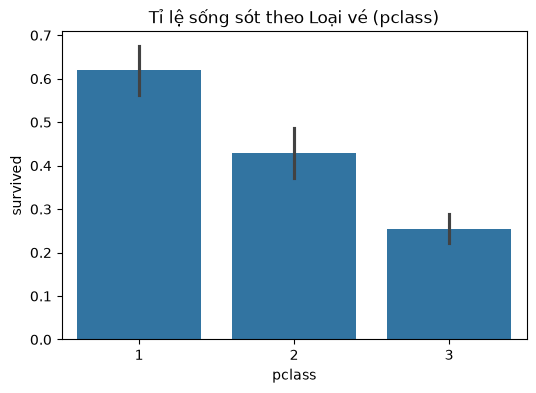

Tỉ lệ sống sót theo pclass:


,count,mean
pclass,,
1,323,0.619
2,277,0.430
3,709,0.255


In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

plt.figure(figsize=(6, 4))
sns.barplot(x="pclass", y="survived", data=df)
plt.title("Tỉ lệ sống sót theo Loại vé (pclass)")
plt.show()

print("Tỉ lệ sống sót theo pclass:")
display(df.groupby("pclass")["survived"].agg(["count", "mean"]).round(3))

**Nhận xét 4.2 (`pclass` vs `survived`):**
- Biểu đồ cột khẳng định rõ sự phân tầng theo hạng vé: hành khách **loại vé 1 (`pclass = 1`)** có tỉ lệ sống sót cao nhất (**61.9%**), tiếp theo là **loại vé 2** (**43.0%**) và thấp nhất là **loại vé 3** (**25.5%**).

Nguyễn Phạm Bảo Khanh - 6451071033


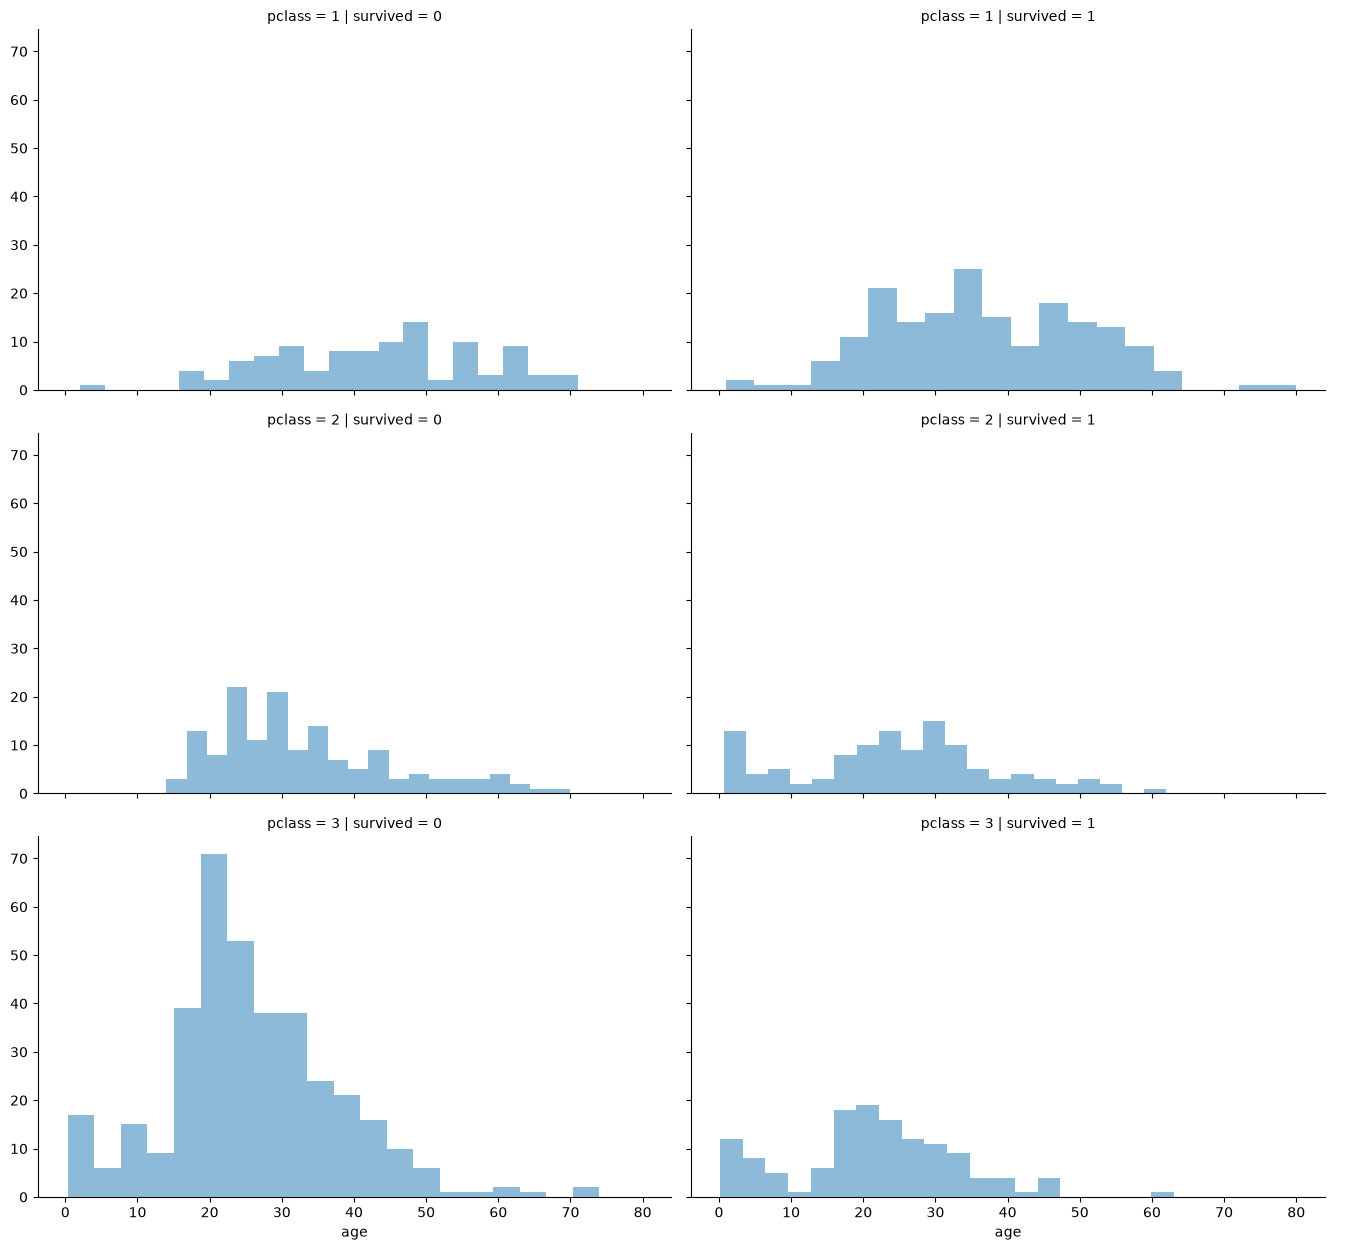

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

grid = sns.FacetGrid(df, col="survived", row="pclass", height=4.2, aspect=1.6)
grid.map(plt.hist, "age", alpha=0.5, bins=20)
grid.add_legend()
plt.show()

**Nhận xét 4.3 (`age` theo `pclass` và `survived`):**
- Biểu đồ histogram phân lưới xác nhận nhận định về `pclass = 1`: số lượng người sống sót (`survived = 1`) ở hạng vé 1 lớn hơn số tử vong ở hầu hết các độ tuổi.
- Ngược lại, ở hạng vé **loại 3 (`pclass = 3`)**, cột `survived = 0` có mật độ tử vong rất cao, đặc biệt tập trung dày đặc ở độ tuổi thanh niên và trung niên trẻ (`18–35` tuổi).

## Câu 5: Thống kê số người đi cùng (`relatives`, `not_alone`) và khảo sát sự liên quan với khả năng sống sót

Nguyễn Phạm Bảo Khanh - 6451071033
Thống kê số hành khách đi một mình (1) vs đi cùng người thân (0):
not_alone
1    790
0    519
Name: count, dtype: int64
-> Số người đi một mình (not_alone=1): 790 người
-> Số người đi cùng người thân (not_alone=0): 519 người

Tỉ lệ sống sót theo số người thân đi cùng (relatives):


,count,mean
relatives,,
0,790,0.303
1,235,0.536
2,159,0.566
3,43,0.698
4,22,0.273
5,25,0.200
6,16,0.250
7,8,0.000
10,11,0.000


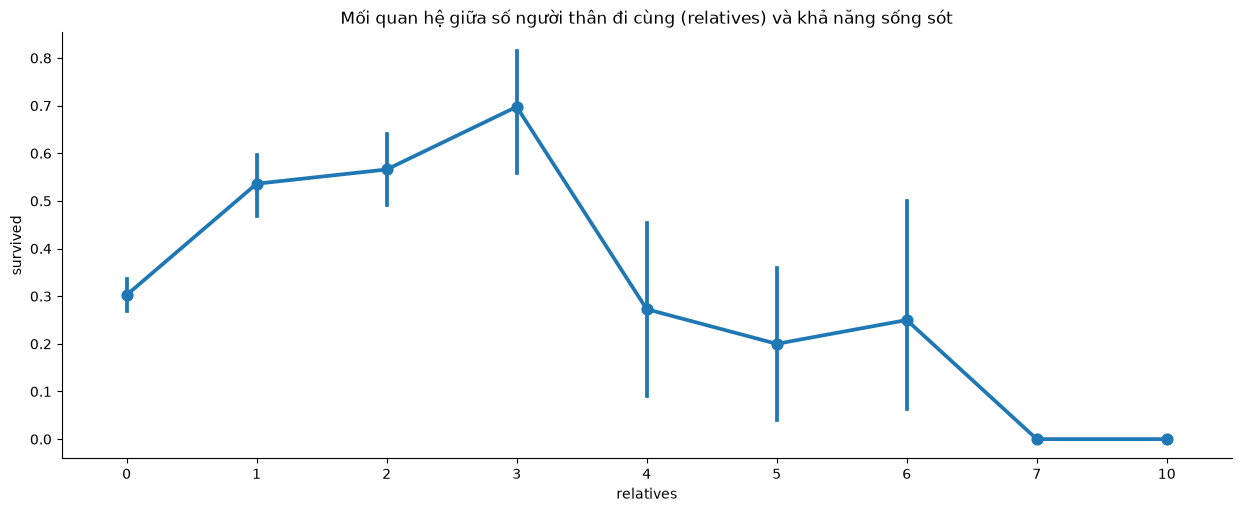

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

df["relatives"] = df["sibsp"] + df["parch"]
df.loc[df["relatives"] > 0, "not_alone"] = 0
df.loc[df["relatives"] == 0, "not_alone"] = 1
df["not_alone"] = df["not_alone"].astype(int)

counts = df["not_alone"].value_counts()
print("Thống kê số hành khách đi một mình (1) vs đi cùng người thân (0):")
print(counts)
print(f"-> Số người đi một mình (not_alone=1): {counts[1]} người")
print(f"-> Số người đi cùng người thân (not_alone=0): {counts[0]} người")

print("\nTỉ lệ sống sót theo số người thân đi cùng (relatives):")
display(df.groupby("relatives")["survived"].agg(["count", "mean"]).round(3))

sns.catplot(x="relatives", y="survived", data=df, aspect=2.5, kind="point")
plt.title("Mối quan hệ giữa số người thân đi cùng (relatives) và khả năng sống sót")
plt.show()

**Nhận xét Câu 5:**
- Trong tổng số 1.309 hành khách, có **790 người** đi một mình (`not_alone = 1`, tỉ lệ sống sót `30.3%`) và **519 người** đi cùng người thân (`not_alone = 0`).
- Từ biểu đồ `catplot`, những người có **1 đến 3 người thân đi cùng** (`relatives = 1, 2, 3`) có tỉ lệ sống sót cao hơn rõ rệt (**53.6% – 69.8%**).
- Ngược lại, các gia đình quá đông (**từ 4 người thân trở lên**) có tỉ lệ sống sót giảm mạnh, đặc biệt nhóm có **7 và 10 người thân** ghi nhận tỉ lệ sống sót thấp nhất (**0%**).

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

import re

# 1. Trích xuất thuộc tính deck từ ký tự đầu của cabin (A..U -> 1..8) trước khi xóa cabin
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df["cabin"] = df["cabin"].fillna("U0")
df["deck"] = df["cabin"].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
df["deck"] = df["deck"].map(deck).fillna(0).astype(int)

# 2. Xem xét thuộc tính ticket (929 giá trị duy nhất) và xóa các cột không cần thiết
print("Thống kê thuộc tính ticket trước khi xóa:")
print(df["ticket"].describe())
df = df.drop(["cabin", "ticket", "boat", "body", "home.dest"], axis=1)

# 3. Điền giá trị thiếu cho age bằng số nguyên ngẫu nhiên trong [mean - std, mean + std]
np.random.seed(42)
mean = df["age"].mean()
std = df["age"].std()
is_null = df["age"].isnull().sum()
rand_age = np.random.randint(mean - std, mean + std, size=is_null)
age_slice = df["age"].copy()
age_slice[np.isnan(age_slice)] = rand_age
df["age"] = age_slice.astype(int)
print(f"\nĐã điền {is_null} giá trị thiếu cho age (seed=42). Số null còn lại ở age: {df['age'].isnull().sum()}")

# 4. Xem xét và điền giá trị thiếu cho embarked bằng giá trị phổ biến nhất ('S')
print("\nThống kê thuộc tính embarked trước khi điền:")
print(df["embarked"].describe())
common_value = "S"
df["embarked"] = df["embarked"].fillna(common_value)

print("\nSố lượng giá trị thiếu còn lại trên từng cột sau Câu 6:")
print(df.isnull().sum())
print("\nCấu trúc dữ liệu sau Câu 6:")
df.info()

Nguyễn Phạm Bảo Khanh - 6451071033
Thống kê thuộc tính ticket trước khi xóa:
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object

Đã điền 263 giá trị thiếu cho age (seed=42). Số null còn lại ở age: 0

Thống kê thuộc tính embarked trước khi điền:
count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object

Số lượng giá trị thiếu còn lại trên từng cột sau Câu 6:
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         1
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64

Cấu trúc dữ liệu sau Câu 6:
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str  

**Nhận xét Câu 6:**
- Đã trích xuất thông tin boong tàu (`deck`: `A..U -> 1..8`, riêng ký tự `'T'` không nằm trong từ điển được ánh xạ về `0` qua `.fillna(0)`) trước khi loại bỏ `cabin`.
- Đã xóa các cột `cabin`, `ticket` (có tới `929` giá trị khác nhau trên `1.309` dòng, dễ gây nhiễu), `boat`, `body`, `home.dest`.
- Đã điền `263` giá trị thiếu của `age` bằng số nguyên ngẫu nhiên trong khoảng `[mean - std, mean + std]` (cố định `np.random.seed(42)` để đảm bảo kết quả tái lập được) và điền `2` giá trị thiếu của `embarked` bằng mode `'S'` (tần suất `914/1307`). Hiện chỉ còn `1` giá trị thiếu ở `fare` sẽ được xử lý ngay ở Câu 7.

## Câu 7: Biến đổi các thuộc tính (`fare`, `title`, `sex`, `embarked`, `age`)

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

# 1. Chuyển đổi giá vé (fare) về kiểu số nguyên (điền 1 giá trị thiếu bằng 0)
df["fare"] = df["fare"].fillna(0).astype(int)

# 2. Trích xuất danh hiệu (title) từ thuộc tính name, ánh xạ 1..5 và xóa cột name
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df["title"] = df["title"].replace(
    ["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"],
    "Rare",
)
df["title"] = df["title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["title"] = df["title"].map(titles).fillna(0).astype(int)
df = df.drop(["name"], axis=1)

print("Phân bố danh hiệu (title - 1:Mr, 2:Miss, 3:Mrs, 4:Master, 5:Rare):")
print(df["title"].value_counts().sort_index())

# 3. Chuyển đổi thuộc tính giới tính (sex) và cổng lên tàu (embarked) thành số
genders = {"male": 0, "female": 1}
ports = {"S": 0, "C": 1, "Q": 2}
df["sex"] = df["sex"].map(genders)
df["embarked"] = df["embarked"].map(ports)

# 4. Chia thuộc tính tuổi (age) thành 8 nhóm (0..7)
df["age"] = df["age"].astype(int)
df.loc[df["age"] <= 11, "age"] = 0
df.loc[(df["age"] > 11) & (df["age"] <= 18), "age"] = 1
df.loc[(df["age"] > 18) & (df["age"] <= 22), "age"] = 2
df.loc[(df["age"] > 22) & (df["age"] <= 27), "age"] = 3
df.loc[(df["age"] > 27) & (df["age"] <= 33), "age"] = 4
df.loc[(df["age"] > 33) & (df["age"] <= 40), "age"] = 5
df.loc[(df["age"] > 40) & (df["age"] <= 66), "age"] = 6
df.loc[df["age"] > 66, "age"] = 7

print("\nPhân bố 8 nhóm tuổi (age: 0..7):")
print(df["age"].value_counts().sort_index())

# 5. Chia thuộc tính giá vé (fare) thành 6 nhóm (0..5) theo ngưỡng PDF trang 16 & 27
df.loc[df["fare"] <= 7.91, "fare"] = 0
df.loc[(df["fare"] > 7.91) & (df["fare"] <= 14.454), "fare"] = 1
df.loc[(df["fare"] > 14.454) & (df["fare"] <= 31), "fare"] = 2
df.loc[(df["fare"] > 31) & (df["fare"] <= 99), "fare"] = 3
df.loc[(df["fare"] > 99) & (df["fare"] <= 250), "fare"] = 4
df.loc[df["fare"] > 250, "fare"] = 5
df["fare"] = df["fare"].astype(int)

print("\nPhân bố 6 nhóm giá vé (fare: 0..5):")
print(df["fare"].value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033
Phân bố danh hiệu (title - 1:Mr, 2:Miss, 3:Mrs, 4:Master, 5:Rare):
title
1    757
2    264
3    198
4     61
5     29
Name: count, dtype: int64

Phân bố 8 nhóm tuổi (age: 0..7):
age
0     91
1    144
2    176
3    214
4    224
5    202
6    249
7      9
Name: count, dtype: int64

Phân bố 6 nhóm giá vé (fare: 0..5):
fare
0    361
1    312
2    325
3    227
4     67
5     17
Name: count, dtype: int64


**Nhận xét Câu 7:**
- **`title`**: Trích xuất đủ 18 danh hiệu từ `name` và gom về 5 nhóm (`Mr`: 757, `Miss`: 264, `Mrs`: 198, `Master`: 61, `Rare`: 29), sau đó xóa cột `name`.
- **`sex` & `embarked`**: Đã mã hóa số (`sex`: `male=0, female=1`; `embarked`: `S=0, C=1, Q=2`).
- **`age` (8 nhóm `0..7`)**: Số lượng hành khách phân bố khá đều ở các nhóm tuổi lao động/thanh niên từ nhóm `1` đến nhóm `6` (từ `144` đến `249` người mỗi nhóm); nhóm trẻ em `<= 11` tuổi (nhóm `0`) có `91` người và nhóm cao tuổi `> 66` tuổi (nhóm `7`) có `9` người.
- **`fare` (6 nhóm `0..5`) & Lưu ý về `qcut()`**:
  - Theo các mốc gợi ý ở trang 16 và mã minh họa trang 27 (`<=7.91`, `(7.91, 14.454]`, `(14.454, 31]`, `(31, 99]`, `(99, 250]`, `>250`), số phần tử ở 4 nhóm đầu khá cân bằng (`361, 312, 325, 227`), còn 2 nhóm vé hạng sang có ít hành khách hơn (`67` và `17`).
  - *Ghi chú kỹ thuật về `qcut()`*: Văn bản trang 27 có đề cập *"sử dụng hàm `qcut()` của thư viện sklearn"* — thực tế `qcut()` là hàm của thư viện **`pandas`** (`pandas.qcut(..., q=6)`), còn trong `scikit-learn` phương thức tương đương là `KBinsDiscretizer(n_bins=6, strategy='quantile')`. Việc chia theo các ngưỡng `.loc` cụ thể từ trang 16/27 giúp giữ nguyên ý nghĩa các mức giá vé (dùng tiếp để tính `fare_per_person` ở Câu 8).

## Câu 8: Tạo các thuộc tính mới (`age_class` và `fare_per_person`) và kiểm tra dữ liệu hoàn chỉnh

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

# Tạo 2 thuộc tính mới
df["age_class"] = df["age"] * df["pclass"]
df["fare_per_person"] = (df["fare"] / (df["relatives"] + 1)).astype(int)

print("--- Kiểm tra giá trị rỗng (isnull().sum()) ---")
null_counts = df.isnull().sum()
print(null_counts)
assert null_counts.sum() == 0, "Vẫn còn giá trị rỗng trong dữ liệu!"

print(f"\nKích thước cuối cùng: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n--- 10 dòng đầu tiên sau khi hoàn tất tiền xử lý (head(10)) ---")
display(df.head(10))

print("\n--- Thông tin kiểu dữ liệu cuối cùng (info()) ---")
df.info()

Nguyễn Phạm Bảo Khanh - 6451071033
--- Kiểm tra giá trị rỗng (isnull().sum()) ---
pclass             0
survived           0
sex                0
age                0
sibsp              0
parch              0
fare               0
embarked           0
relatives          0
not_alone          0
deck               0
title              0
age_class          0
fare_per_person    0
dtype: int64

Kích thước cuối cùng: 1309 dòng, 14 cột

--- 10 dòng đầu tiên sau khi hoàn tất tiền xử lý (head(10)) ---


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3



--- Thông tin kiểu dữ liệu cuối cùng (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   pclass           1309 non-null   int64
 1   survived         1309 non-null   int64
 2   sex              1309 non-null   int64
 3   age              1309 non-null   int64
 4   sibsp            1309 non-null   int64
 5   parch            1309 non-null   int64
 6   fare             1309 non-null   int64
 7   embarked         1309 non-null   int64
 8   relatives        1309 non-null   int64
 9   not_alone        1309 non-null   int64
 10  deck             1309 non-null   int64
 11  title            1309 non-null   int64
 12  age_class        1309 non-null   int64
 13  fare_per_person  1309 non-null   int64
dtypes: int64(14)
memory usage: 143.3 KB


**Kết luận Câu 8:**
- Đã tạo thành công hai thuộc tính mới: `age_class = age * pclass` (phản ánh tương tác giữa nhóm tuổi và hạng vé) và `fare_per_person = int(fare / (relatives + 1))` (làm trơn `+ 1` để tính giá vé bình quân theo quy mô gia đình và tránh chia cho 0).
- Tập dữ liệu sau tiền xử lý gồm **1.309 dòng × 14 cột**, toàn bộ đều mang kiểu số nguyên (`int64`) và **không còn bất kỳ giá trị thiếu (`null`) nào** (`isnull().sum() == 0` trên tất cả các cột), sẵn sàng cho các thuật toán khai phá dữ liệu và học máy.